In [1]:
from sympy import * #symbols, limit, oo, diff, solve, init_printing, pprint
init_printing()

import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Q 1: 

Find equation of line and demonstrate your solution using plots: 

A) passing through points $(x_1, y_1) \equiv (-1, 5)$ and $(x_2, y_2) \equiv (2, 2)$:

B) with slope $m = \frac{1}{2}$ and passing through point $(3, 2)$

Note: You may use pen(cil) and paper to find the answer and simply plot it in Python

Equation of line: y = (-3/4) x + 7/2


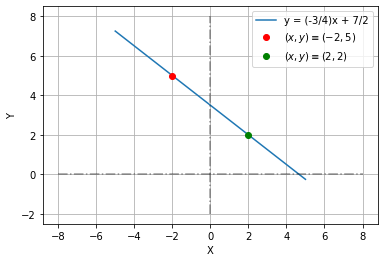

In [2]:
# do not run this cell:

## Q 1. A:

m, c = symbols('m c')
x1, y1 = -2, 5
x2, y2 = 2, 2

f1 = y1 - m*x1 - c
f2 = y2 - m*x2 - c

res = solve([f1, f2])
print(f'Equation of line: y = ({res[m]}) x + {res[c]}')

x_ = np.linspace(-5, 5)
plt.plot(x_, res[m]*x_ + res[c], label=f'y = ({res[m]})x + {res[c]}')
plt.grid()
plt.plot(np.linspace(-8, 8), [0]*len(np.linspace(-8, 8)), '-.k', alpha=0.4)
plt.plot([0]*len(np.linspace(-8, 8)), np.linspace(-2, 8), '-.k', alpha=0.4)
plt.plot(-2, 5, 'ro', label = r'$(x, y) \equiv (-2, 5)$')
plt.plot(2, 2, 'go', label = r'$(x, y) \equiv (2, 2)$')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

In [3]:
# write your code here:


Equation of line: y = (1/2) x + 1/2


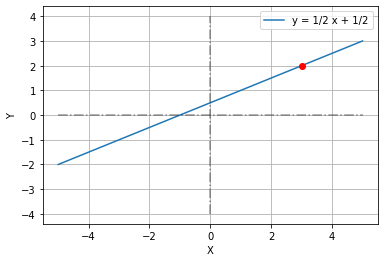

In [4]:
# do not run this cell:

## Q 1. B:

c = symbols('c')
x1, y1 = 3, 2
m = Rational(1, 2)

f1 = y1 - m*x1 - c

res = solve(f1)[0]
res
print(f'Equation of line: y = ({m}) x + {res}')

x_ = np.linspace(-5, 5)
plt.plot(x_, m*x_ + res, label=f'y = {m} x + {res}')
plt.grid()
plt.plot(np.linspace(-5, 5), [0]*len(np.linspace(-5, 5)), '-.k', alpha=0.4)
plt.plot([0]*len(np.linspace(-5, 5)), np.linspace(-4, 4), '-.k', alpha=0.4)
plt.plot(3, 2, 'ro')
y = np.linspace(0, -5)
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

In [5]:
# write your code here:


## Q 2: 

A) Find zeros of the function: $f(x) = x^2 -8x -9$

B) Find $\text{x-intercept}$ and $\text{y-intercept}$ for the function: $x^3 - 2x^2 + 8$
        
    
Note: Produce necessary plots to demonstrate all your solutions

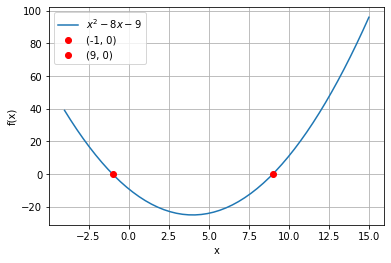

In [3]:
# do not run this cell:
# Q 2. A:

x = symbols('x')
f = x**2 -8*x - 9
zeros = solve(f)

f_ = lambdify(x, f)

x_ = np.linspace(-4, 15)
plt.plot(x_, f_(x_), label=r'$x^2 - 8x - 9$')
plt.plot(zeros[0], 0, 'or', label=f'({zeros[0]}, 0)')
plt.plot(zeros[1], 0, 'or', label=f'({zeros[1]}, 0)')
plt.grid()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()

In [4]:
# write your code here: 


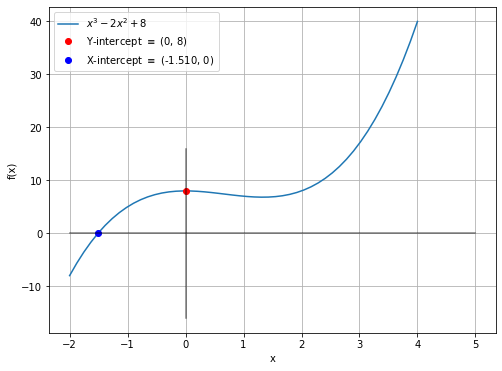

In [29]:
# do not run this cell:
# Q 2. B:

x = symbols('x', real=True)
# f = x**3 - 3*x**2 + 2
f = x**3 - 2*x**2 + 8

y_intercept = f.subs({x : 0})

zeros = solve(f)
zeros = [round(re(zero).n(), 3) for zero in zeros]

f_ = lambdify(x, f)

plt.figure(figsize=(8, 6))
x_ = np.linspace(-2, 4)
plt.plot(x_, f_(x_), label=r'$x^3 - 2x^2 + 8$')
plt.plot(0, y_intercept, 'or', label=rf'Y-intercept $\equiv$ (0, {y_intercept})')
plt.plot(zeros[2], 0, 'ob', label=rf'X-intercept $\equiv$ ({zeros[2]}, 0)')
plt.plot(np.linspace(-2, 5), [0]*len(np.linspace(-2, 5)), '-k', alpha=0.5)
plt.plot([0]*len(np.linspace(-16, 16)), np.linspace(-16, 16), '-k', alpha=0.5)

plt.grid()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()

In [18]:
# write your code here: 
re(solve(f)[2]).n()

In [26]:
[complex(round(re(x), 3), round(im(x), 3)) for x in solve(f)]

[(1.7550048828125+1.4900054931640625j),
 (1.7550048828125-1.4900054931640625j),
 (-1.5099945068359375+0j)]

In [ ]:
complex

## Q 3: 

Compute derivatives of the function, `h(t)`, and draw tangent segments at specified points:

$h(t) = e^t \cdot \text{sin} (30 \ t)$ at $t = -0.25, 0.03, 0.5$


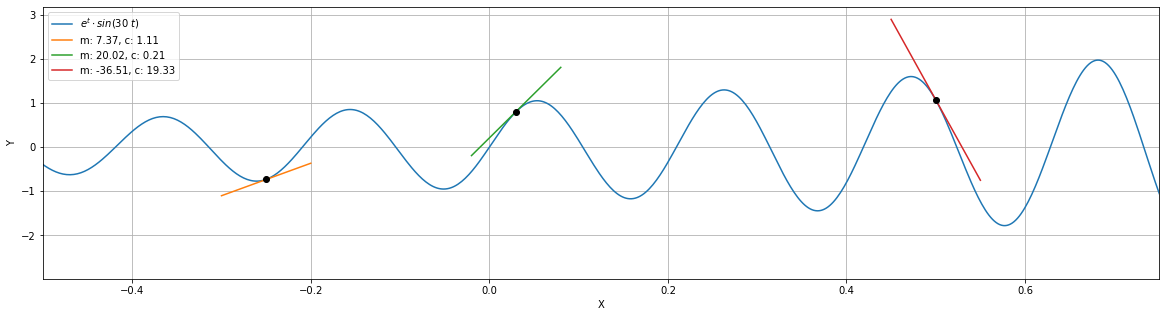

In [10]:
# do not run this cell:

# Q3:
x = symbols('x')

def derivative(f, x0):
    x = symbols('x')
    h = 1e-5
    m = ((f.subs(x, x0 + h).n() - f.subs(x, x0).n())/h).round(2)
    c = (f.subs(x, x0) - m*x0).round(2)
    return m, c


f = exp(x)*sin(30*x)
x0s = [-0.25, 0.03, 0.5]


f_ = lambdify(x, f)
x_ = np.linspace(-1, 1, 1000)

plt.figure(figsize=(20, 5))
plt.plot(x_, f_(x_), label=r'$e^t \cdot sin (30 \ t)$')
plt.grid()
plt.xlabel('X')
plt.ylabel('Y')

ms, cs = [], []
for x0 in (x0s):
    m, c = derivative(f, x0)
    x_ = np.linspace(x0-0.05, x0+0.05)
    plt.plot(x_, m*x_ + c, label=f'm: {m}, c: {c}')
    plt.plot(x0, f.subs(x, x0), 'ok')
    plt.xlim([-0.5, 0.75])
    

plt.legend()

In [11]:
# write your code here: 


## Q 4: 

Determine whether the function, `f(x)`, is increasing or decreasing at specified points:

$f(x) = x^3$ at $x = -1, 0, 1$

3.00000000000000
3.00000000000000
3.00000000000000
x**3 is increasing at x = -1
0.0
x**3 is at critical point at x = 0
3.00000000000000
3.00000000000000
3.00000000000000
x**3 is increasing at x = 1


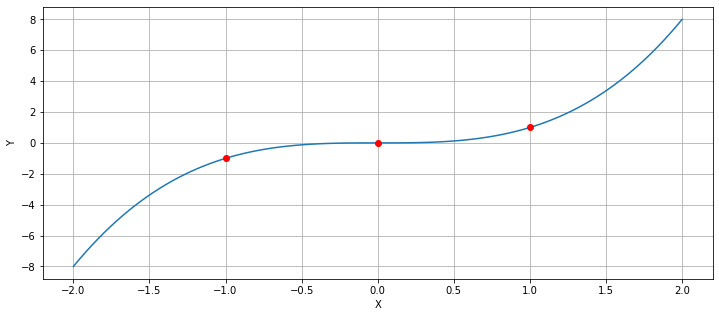

In [30]:
# do not run this cell:

# Q4:

x = symbols('x')

def derivative(f, x0):
    h = 1e-10
    print(((f.subs(x, x0 + h).n() - f.subs(x, x0).n())/h).round(4))
    return ((f.subs(x, x0 + h).n() - f.subs(x, x0).n())/h).round(4)

def increasing_or_decreasing(f, x0):
    if derivative(f, x0) == 0:
        return f'{f} is at critical point at x = {x0}'
    elif derivative(f, x0) < 0:
        return f'{f} is decreasing at x = {x0}'
    elif derivative(f, x0) > 0:
        return f'{f} is increasing at x = {x0}'
    
    
f = x**3
x0s = [-1, 0, 1]

for x0 in x0s:
    print(increasing_or_decreasing(f, x0))
    
    
plt.figure(figsize=(12, 5))
X = np.linspace(-2, 2, 100)
f_fun = lambdify(x, f)
plt.plot(X, f_fun(X))
plt.plot(-1, f_fun(-1), 'ro')
plt.plot(0, f_fun(0), 'ro')
plt.plot(1, f_fun(1), 'ro')
plt.grid()
plt.xlabel('X')
plt.ylabel('Y');

In [13]:
# write your code here: 


## Q 5: 

Find extremum points, minima, and maxima of the function $x^2 - 4 x$ in the interval $[-1, 4]$.


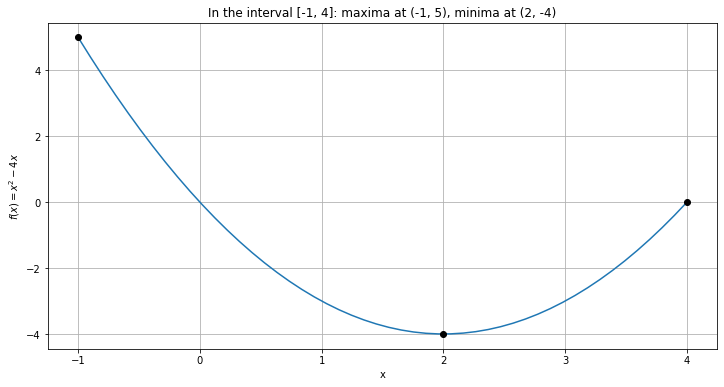

In [14]:
# do not run this cell:
# Q5:

x = symbols('x')
f = x**2 -4*x

a, b = [-1, 4]
minima = solve(diff(f, x), x)[0]
f_ = lambdify(x, f)
x_ = np.linspace(a, b)

plt.figure(figsize=(12, 6))
plt.plot(x_, f_(x_))
plt.plot(a, f_(a), 'ok')
plt.plot(b, f_(b), 'ok')
plt.plot(minima, f_(minima), 'ok')
plt.xlabel('x')
plt.ylabel(r'$f(x) = x^2 - 4 x$')
plt.title(f'In the interval {[a, b]}: maxima at ({-1}, {f_(-1)}), minima at ({minima}, {f_(minima)})')
plt.grid()

In [15]:
# write your code here:


## Q 6: 

Find area of the region enclosed by the functions (or curves): 


A) $y = \frac{2}{x}$ and $y = -x + 3$

B) $y = -x + 10$, $y = 4 x$ and $y = 2 x$

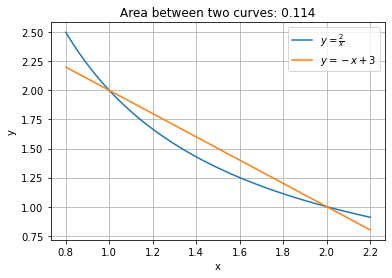

In [16]:
# do not run this cell:

# Q6. A:

x = symbols('x')

f1 = 2/x
f2 = -x + 3

f1_ = lambdify(x, f1)
f2_ = lambdify(x, f2)

a, b = solve(f1 - f2, x)
area = (integrate(f2, (x, a, b)) - integrate(f1, (x, a, b))).n().round(3)

x_ = np.linspace(0.8, 2.2)
plt.plot(x_, f1_(x_), label = r'$y = \frac{2}{x}$')
plt.plot(x_, f2_(x_), label = r'$y = -x + 3$')

plt.grid()
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title(f'Area between two curves: {area}');

In [17]:
# write your code here:


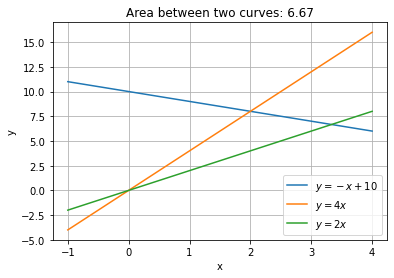

In [18]:
# do not run this cell:

# Q6. B:

x = symbols('x')

f1 = -x + 10
f2 = 4*x
f3 = 2*x

f1_ = lambdify(x, f1)
f2_ = lambdify(x, f2)
f3_ = lambdify(x, f3)

a = solve(f2-f3, x)[0]
b = solve(f1-f2, x)[0]
c = solve(f1-f3, x)[0]

area1 = integrate(f2, (x, a, b)) - integrate(f3, (x, a, b))
area2 = integrate(f1, (x, b, c)) - integrate(f3, (x, b, c))
area = (area1 + area2).n().round(2)

x_ = np.linspace(-1, 4)

plt.plot(x_, f1_(x_), label = r'$y = -x + 10$')
plt.plot(x_, f2_(x_), label = r'$y = 4 x$')
plt.plot(x_, f3_(x_), label = r'$y = 2 x$')
plt.grid()
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.title(f'Area between two curves: {area}');

In [19]:
# write your code here:


## Q 7: 

Find Taylor series expansion of the function: 

$sin \ x \cdot cos \ x$ at $x = -0.5$

In [20]:
import math

def compute_nth_derivative(f, n):
    x = symbols('x')
    for i in range(1, n+1):
        f = diff(f, x)
    return f

How many derivatives you want to compute? 6


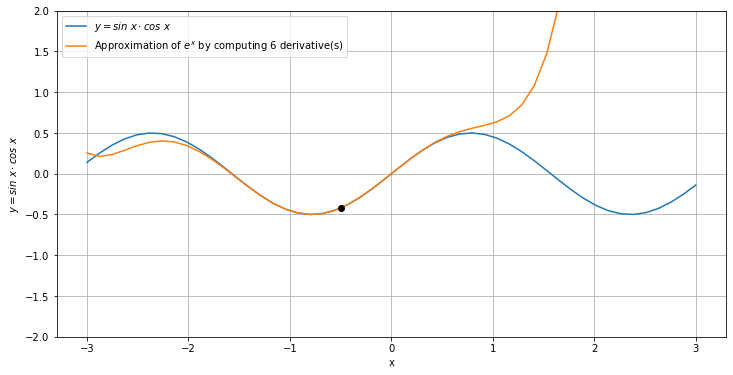

In [21]:
# do not run this cell:

f = sin(x)*cos(x)
a = -0.5

f_approx = f.subs(x, a)


n = int(input('How many derivatives you want to compute? '))

for i in range(1, n+1):
    f_approx += compute_nth_derivative(f, i).subs(x, a)*(x-a)**i/math.factorial(i)
    
f_ = lambdify(x, f)
f_approx_ = lambdify(x, f_approx)

plt.figure(figsize=(12, 6))
x_ = np.linspace(-3, 3)
plt.plot(x_, f_(x_), label=r'$y = sin \ x \cdot cos \ x$')
plt.plot(x_, f_approx_(x_), label=fr'Approximation of $e^x$ by computing {i} derivative(s)')
plt.plot(a, f.subs(x, a), 'ok')
plt.grid()
plt.legend()
plt.ylim([-2, 2])
plt.xlabel('x')
plt.ylabel(r'$y = sin \ x \cdot cos \ x$');

In [22]:
# write your code here:


## Q 8: 

Find Maclaurin series expansion of the function $sin \ x \cdot cos \ x$

In [25]:
# do not run this cell:

def compute_nth_derivative(f, n):
    x = symbols('x')
    for i in range(1, n+1):
        f = diff(f, x)
    return f

def compute_maclaurin_series(f, n):
    x = symbols('x')
    f_approx = f.subs(x, 0)
    for i in range(1, n+1):
        f_approx += compute_nth_derivative(f, i).subs(x, 0)*(x)**i/math.factorial(i)
    return f_approx

f = sin(x)*cos(x)
f_maclaurin = compute_maclaurin_series(f, 10)
pprint(f_maclaurin)

   9      7      5      3    
2⋅x    4⋅x    2⋅x    2⋅x     
──── - ──── + ──── - ──── + x
2835   315     15     3      


In [ ]:
# write your code here: 
